# VC · Práctica 5 — Entrenamiento de la CNN en PyTorch (FER-2013)

Este notebook **solo entrena** la CNN en PyTorch y la valida. No evalúa en `test` ni compara con otros modelos (eso va en el notebook de comparativa).

* `test/` **no se toca** aquí: se reserva para la evaluación final.
* Las decisiones (qué época es mejor) se toman con la **validación** (20 % estratificado de `train`).
* El modelo se guarda en `outputs_p5/models/v1_CNN_torch` con la seed en el nombre, para no pisar versiones anteriores.

**Índice:** 1. Configuración y semilla · 2. Datos · 3. Modelo PyTorch · 4. Entrenamiento · 5. Curvas y validación · 6. Guardado

In [1]:
import os, time, json, copy, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from tqdm.auto import tqdm

## 1. Configuración y semilla

In [2]:
# ==========================================================
# 1. RANDOMNESS AND TRAINING SEED
# ==========================================================

SEED = 42

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)


set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [3]:
# =====================  PARÁMETROS  =====================
DATA_DIR = Path(r"/home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset")
TRAIN_DIR = DATA_DIR / "train"

IMG_SIZE = 48
VAL_SIZE = 0.20

# Datos
BALANCE_TRAIN = False  # True = submuestrea train a igual nº de imágenes por clase
PER_CLASS_CAP = (
    None  # None = igualar a la clase más pequeña; p.ej. 2000 = tope por clase
)

# Arquitectura / regularización
FILTERS =  [48, 96, 192, 384]
DROPOUTS = [0.05, 0.10, 0.15, 0.20]
HEAD_UNITS = 256
HEAD_DROPOUT = 0.40
AUG_ROTATION_DEG = 10.8  # ~0.03 * 2π rad ≈ ±10.8°
AUG_ZOOM = 0.10

# Entrenamiento
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS, BATCH = 80, 64
ES_PATIENCE, LR_PATIENCE = 12, 4

OUT_DIR = Path("outputs_p5")
MODELS_DIR = OUT_DIR / "models/v1_CNN_torch"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAME = f"cnn_fer_torch_seed{SEED}"
MODEL_PATH = MODELS_DIR / f"{MODEL_NAME}.pt"

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TRAIN_DIR.is_dir(), f"No encuentro train/ en {DATA_DIR}"
print(
    f"PyTorch {torch.__version__} | device: {device}"
    + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
)

PyTorch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 3060 Ti)


## 2. Datos
Solo se carga `train/`. Las imágenes se leen con `np.fromfile` + `cv2.imdecode`.

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def read_gray(path: Path):
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is not None and img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img

CLASS_NAMES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
N_CLASSES = len(CLASS_NAMES)

X_full, y_full = [], []
for idx, cname in enumerate(CLASS_NAMES):
    files = sorted(f for f in (TRAIN_DIR / cname).iterdir() if f.suffix.lower() in IMG_EXT)
    for f in tqdm(files, desc=cname, leave=False):
        img = read_gray(f)
        if img is not None:
            X_full.append(img); y_full.append(idx)
X_full = np.stack(X_full).astype(np.uint8); y_full = np.array(y_full, dtype=np.int64)
print("Clases:", CLASS_NAMES, "| train completo:", X_full.shape)

# --- Validación estratificada 80/20 ---
idx_tr, idx_val = train_test_split(np.arange(len(y_full)), test_size=VAL_SIZE, stratify=y_full, random_state=SEED)
X_tr,  y_tr  = X_full[idx_tr],  y_full[idx_tr]
X_val, y_val = X_full[idx_val], y_full[idx_val]

# # --- (Opcional) train balanceado ---
# if BALANCE_TRAIN:
#     rng = np.random.default_rng(SEED)
#     counts = np.bincount(y_tr, minlength=N_CLASSES); cap = PER_CLASS_CAP or counts.min()
#     sel = np.concatenate([rng.choice(np.where(y_tr == c)[0], min(cap, counts[c]), replace=False) for c in range(N_CLASSES)])
#     rng.shuffle(sel); X_tr, y_tr = X_tr[sel], y_tr[sel]

# --- class_weight (solo con el train usado para entrenar) ---
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
cw = cw ** 0.5  # suavizado (opcional)
cw = cw /cw.mean()  # normalizado a N_CLASSES
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
cw_tensor = torch.tensor(cw, dtype=torch.float32)

print(f"train: {len(y_tr)} | val: {len(y_val)}")
print(pd.DataFrame({"train": np.bincount(y_tr, minlength=N_CLASSES),
                    "val": np.bincount(y_val, minlength=N_CLASSES),
                    "class_weight": np.round(list(CLASS_WEIGHTS.values()), 2)}, index=CLASS_NAMES))

# DataLoaders (entrada uint8 (N, 1, 48, 48), rango 0-255)
def make_loader(X_arr, y_arr, batch_size=BATCH, shuffle=False):
    x_t = torch.from_numpy(X_arr[:, None, :, :])  # (N, 1, 48, 48) uint8
    y_t = torch.from_numpy(y_arr).long()
    ds = TensorDataset(x_t, y_t)
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen, pin_memory=(device.type == "cuda"))

train_loader = make_loader(X_tr, y_tr, batch_size=BATCH, shuffle=True)
val_loader   = make_loader(X_val, y_val, batch_size=256, shuffle=False)

angry:   0%|          | 0/3995 [00:00<?, ?it/s]

disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

happy:   0%|          | 0/7215 [00:00<?, ?it/s]

neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

sad:   0%|          | 0/4830 [00:00<?, ?it/s]

surprised:   0%|          | 0/3171 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised'] | train completo: (28709, 48, 48)
train: 22967 | val: 5742
           train   val  class_weight
angry       3196   799          0.81
disgusted    349    87          2.44
fearful     3277   820          0.80
happy       5772  1443          0.60
neutral     3972   993          0.72
sad         3864   966          0.73
surprised   2537   634          0.90


## 3. Modelo PyTorch
4 bloques `Conv2d → BatchNorm2d → ReLU` (×2) + `MaxPool2d` + `Dropout2d`, cabeza `AdaptiveAvgPool2d + Linear`.
El **aumento de datos** y el reescalado `/255` van dentro del modelo: el aumento solo se activa en `model.train()` y la **entrada es la cara en gris 48×48 con valores 0-255**.

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, drop: float):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(p=drop),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class CNNFer(nn.Module):
    def __init__(
        self,
        in_channels: int = 1,
        n_classes: int = N_CLASSES,
        filters: list[int] = FILTERS,
        dropouts: list[float] = DROPOUTS,
        head_units: int = HEAD_UNITS,
        head_dropout: float = HEAD_DROPOUT,
        aug_rotation_deg: float = AUG_ROTATION_DEG,
        aug_zoom: float = AUG_ZOOM,
    ):
        super().__init__()
        self.augment = nn.Sequential(
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomAffine(
                degrees=aug_rotation_deg,
                translate=(0.08, 0.08),
                scale=(1.0 - aug_zoom, 1.0 + aug_zoom),
            ),
            v2.ColorJitter(brightness=0.2, contrast=0.2),
            v2.RandomErasing(p=0.25, scale=(0.02, 0.12)),
        )

        blocks = []
        ch = in_channels
        for f, d in zip(filters, dropouts):
            blocks.append(ConvBlock(ch, f, d))
            ch = f
        self.features = nn.Sequential(*blocks)

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(ch, head_units, bias=False),
            nn.BatchNorm1d(head_units),
            nn.ReLU(inplace=True),
            nn.Dropout(p=head_dropout),
            nn.Linear(head_units, n_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Acepta (B, 1, 48, 48) o (B, 48, 48, 1) en rango 0-255
        if x.ndim == 4 and x.shape[-1] == 1 and x.shape[1] != 1:
            x = x.permute(0, 3, 1, 2)
        x = x.to(dtype=torch.float32) / 255.0
        if self.training:
            x = self.augment(x)
        x = self.features(x)
        x = self.gap(x)
        return self.head(x)


set_seed(SEED)
model = CNNFer().to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Total params: {total_params:,} | Trainable params: {trainable_params:,}")

CNNFer(
  (augment): Sequential(
    (0): RandomHorizontalFlip(p=0.5)
    (1): RandomAffine(degrees=[-10.8, 10.8], translate=(0.08, 0.08), scale=(0.9, 1.1), interpolation=nearest, fill=0)
    (2): ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2))
    (3): RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=[0.0], inplace=False)
  )
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.05, i

## 4. Entrenamiento
`CrossEntropyLoss(weight=cw_tensor)` + `AdamW` + `ReduceLROnPlateau` + `EarlyStopping` (guarda y restaura los mejores pesos según `val_loss`).

In [7]:
criterion = nn.CrossEntropyLoss(weight=cw_tensor.to(device), label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=LR_PATIENCE, min_lr=1e-6
)

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": [], "lr": []}
best_val_loss = float("inf")
best_ep = 0
best_weights = copy.deepcopy(model.state_dict())
epochs_no_improve = 0

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    ep_t0 = time.time()
    # --- Train ---
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        bs = yb.size(0)
        tr_loss_sum += loss.item() * bs
        tr_correct += (logits.argmax(dim=1) == yb).sum().item()
        tr_total += bs

    # --- Validation ---
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            logits = model(xb)
            loss = criterion(logits, yb)

            bs = yb.size(0)
            val_loss_sum += loss.item() * bs
            val_correct += (logits.argmax(dim=1) == yb).sum().item()
            val_total += bs

    tr_loss = tr_loss_sum / tr_total
    tr_acc  = tr_correct / tr_total
    val_loss = val_loss_sum / val_total
    val_acc  = val_correct / val_total
    cur_lr = optimizer.param_groups[0]["lr"]

    history["loss"].append(tr_loss)
    history["accuracy"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["lr"].append(cur_lr)

    scheduler.step(val_loss)
    ep_sec = time.time() - ep_t0
    print(
        f"Epoch {epoch:02d}/{EPOCHS} - {ep_sec:.1f}s - "
        f"loss: {tr_loss:.4f} - accuracy: {tr_acc:.4f} - "
        f"val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f} - lr: {cur_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_ep = epoch - 1
        best_weights = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= ES_PATIENCE:
            print(f"Early stopping en época {epoch}. Restaurando mejores pesos de la época {best_ep + 1}.")
            break

model.load_state_dict(best_weights)
train_minutes = (time.time() - t0) / 60
print(f"Entrenamiento terminado en {train_minutes:.1f} min (mejor época: {best_ep + 1})")

Epoch 01/80 - 9.2s - loss: 1.9998 - accuracy: 0.2223 - val_loss: 1.9622 - val_accuracy: 0.2680 - lr: 0.001000
Epoch 02/80 - 8.2s - loss: 1.8889 - accuracy: 0.3072 - val_loss: 1.7417 - val_accuracy: 0.4039 - lr: 0.001000
Epoch 03/80 - 8.4s - loss: 1.7387 - accuracy: 0.4178 - val_loss: 1.6570 - val_accuracy: 0.4469 - lr: 0.001000
Epoch 04/80 - 8.8s - loss: 1.6641 - accuracy: 0.4549 - val_loss: 1.5508 - val_accuracy: 0.5165 - lr: 0.001000
Epoch 05/80 - 8.7s - loss: 1.6001 - accuracy: 0.4926 - val_loss: 1.5584 - val_accuracy: 0.5214 - lr: 0.001000
Epoch 06/80 - 8.4s - loss: 1.5640 - accuracy: 0.5143 - val_loss: 1.5277 - val_accuracy: 0.5078 - lr: 0.001000
Epoch 07/80 - 8.4s - loss: 1.5304 - accuracy: 0.5287 - val_loss: 1.4730 - val_accuracy: 0.5432 - lr: 0.001000
Epoch 08/80 - 8.3s - loss: 1.5063 - accuracy: 0.5440 - val_loss: 1.4342 - val_accuracy: 0.5589 - lr: 0.001000
Epoch 09/80 - 8.2s - loss: 1.4843 - accuracy: 0.5534 - val_loss: 1.4165 - val_accuracy: 0.5700 - lr: 0.001000
Epoch 10/8

## 5. Curvas y validación

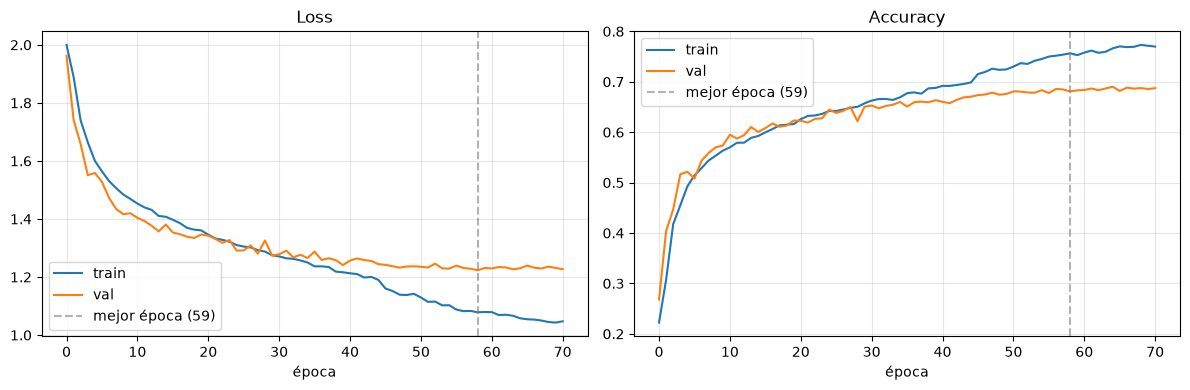

Mejor época: 59 | val_loss=1.2233 | val_accuracy=0.6808


In [8]:
h = history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
for a in ax:
    a.axvline(best_ep, color="gray", ls="--", alpha=.6, label=f"mejor época ({best_ep + 1})")
    a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Mejor época: {best_ep + 1} | val_loss={h['val_loss'][best_ep]:.4f} | val_accuracy={h['val_accuracy'][best_ep]:.4f}")

Validación -> accuracy=0.6897 | F1-macro=0.6724

              precision    recall  f1-score   support

       angry       0.61      0.58      0.60       799
   disgusted       0.64      0.72      0.68        87
     fearful       0.56      0.55      0.55       820
       happy       0.88      0.88      0.88      1443
     neutral       0.62      0.71      0.66       993
         sad       0.60      0.50      0.54       966
   surprised       0.76      0.83      0.79       634

    accuracy                           0.69      5742
   macro avg       0.67      0.68      0.67      5742
weighted avg       0.69      0.69      0.69      5742



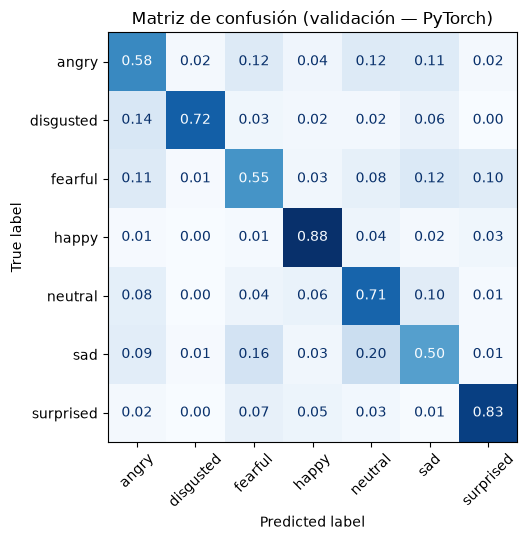

In [9]:
@torch.no_grad()
def predict_probs(
    net: nn.Module,
    X_arr: np.ndarray,
    batch_size: int = 256,
    use_tta: bool = True,
) -> np.ndarray:
    net.eval()
    probs_list = []
    for i in range(0, len(X_arr), batch_size):
        xb = torch.from_numpy(X_arr[i:i + batch_size, None, :, :]).to(device)
        probs = F.softmax(net(xb), dim=-1)
        if use_tta:
            probs_flip = F.softmax(net(torch.flip(xb, dims=[-1])), dim=-1)
            probs = 0.5 * (probs + probs_flip)
        probs_list.append(probs.cpu().numpy())
    return np.concatenate(probs_list, axis=0)

p_val = predict_probs(model, X_val, use_tta=True)
y_pred_val = p_val.argmax(1)
val_f1_macro = f1_score(y_val, y_pred_val, average="macro")
print(f"Validación -> accuracy={np.mean(y_pred_val == y_val):.4f} | F1-macro={val_f1_macro:.4f}\n")
print(classification_report(y_val, y_pred_val, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_val, y_pred_val, labels=range(N_CLASSES), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False,
                                                            xticks_rotation=45, values_format=".2f")
ax.set_title("Matriz de confusión (validación — PyTorch)"); plt.tight_layout(); plt.show()

## 6. Guardado
Se guarda el checkpoint `.pt` (pesos óptimos + hiperparámetros de arquitectura), los nombres de clase, el historial y la configuración JSON.

In [11]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "arch": {
        "in_channels": 1,
        "n_classes": N_CLASSES,
        "filters": FILTERS,
        "dropouts": DROPOUTS,
        "head_units": HEAD_UNITS,
        "head_dropout": HEAD_DROPOUT,
        "aug_rotation_deg": AUG_ROTATION_DEG,
        "aug_zoom": AUG_ZOOM,
    },
}
torch.save(checkpoint, MODEL_PATH)
json.dump(CLASS_NAMES, open(MODELS_DIR / "class_names.json", "w"))
pd.DataFrame(history).to_csv(MODELS_DIR / f"{MODEL_NAME}_history.csv", index=False)

config = dict(
    framework="pytorch",
    seed=SEED,
    balance_train=BALANCE_TRAIN,
    per_class_cap=PER_CLASS_CAP,
    filters=FILTERS,
    dropouts=DROPOUTS,
    head_units=HEAD_UNITS,
    head_dropout=HEAD_DROPOUT,
    aug_rotation_deg=AUG_ROTATION_DEG,
    aug_zoom=AUG_ZOOM,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs_run=len(h["loss"]),
    best_epoch=best_ep + 1,
    val_loss=float(h["val_loss"][best_ep]),
    val_accuracy=float(np.mean(y_pred_val == y_val)),
    val_f1_macro=float(val_f1_macro),
    train_minutes=round(train_minutes, 1),
)
json.dump(config, open(MODELS_DIR / f"{MODEL_NAME}_config.json", "w"), indent=2)

# Comprobación: el .pt recarga bien y da las mismas predicciones
ckpt = torch.load(MODEL_PATH, map_location=device, weights_only=True)
reloaded = CNNFer(**ckpt["arch"]).to(device)
reloaded.load_state_dict(ckpt["model_state_dict"])

p_orig = predict_probs(model, X_val[:64], use_tta=True)
p_reload = predict_probs(reloaded, X_val[:64], use_tta=True)
same = np.allclose(p_reload, p_orig, atol=1e-5)
print("Modelo guardado en:", MODEL_PATH.resolve(), "| recarga OK:", same)

Modelo guardado en: /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_CNN_torch/cnn_fer_torch_seed42.pt | recarga OK: True
